# Final report-grade visualization and analysis

This notebook is a cleaned, metadata-driven version of the benchmark visualization report.  
It contains **no unanswered prompts** and no placeholders requiring manual writing.

The analysis uses:

- `executive_summary.csv`
- `normalized_summary_all.csv`
- `figure_manifest.csv`
- `figure_commentary_auto.md`

The report evaluates CPU, Pi5, and GPU/vLLM runs across MMLU, GSM8K, HellaSwag, and Dolly.


## Executive interpretation

The benchmark should be read as a multi-objective deployment analysis rather than as a single leaderboard.  
For MMLU, GSM8K, and HellaSwag, **accuracy is the qualifying metric**. Latency, throughput, RAM, temperature, power, and energy are meaningful only after verifying that the model is accurate enough for the task.

For Dolly, no correctness score is computed by the benchmark runner. Dolly is therefore interpreted as a **generation-performance workload**, not as a quality benchmark.


## Key factual results from the metadata

- For MMLU, the highest accuracy is achieved by **phi4_14b_bf16** on **vllm** with **0.82**.
- For MMLU, the lowest latency is achieved by **llama3_2_1b_bf16** on **vllm** with **239.4**.
- For MMLU, the highest throughput is achieved by **phi4mini_bf16** on **vllm** with **23.89**.
- For GSM8K, the highest accuracy is achieved by **llama3_3_70b_fp8** on **vllm** with **0.75**.
- For GSM8K, the lowest latency is achieved by **llama3_2_1b_bf16** on **vllm** with **1,098**.
- For GSM8K, the highest throughput is achieved by **llama3_2_1b_bf16** on **vllm** with **116.7**.
- For HELLASWAG, the highest accuracy is achieved by **phi4_14b_bf16** on **vllm** with **0.85**.
- For HELLASWAG, the lowest latency is achieved by **llama3_2_1b_bf16** on **vllm** with **240.6**.
- For HELLASWAG, the highest throughput is achieved by **phi4mini_bf16** on **vllm** with **31.67**.
- For DOLLY, the lowest latency is achieved by **llama3_2_1b_bf16** on **vllm** with **1,120**.
- For DOLLY, the highest throughput is achieved by **llama3_2_1b_bf16** on **vllm** with **116.9**.
- For DOLLY, the lowest estimated energy is achieved by **llama3_2_1b_bf16** on **vllm** with **145.5**.


## Platform-specific findings

### CPU
- **MMLU** — accuracy: **Ministral-3-3B-Instruct-2512-Q4_K_M.gguf** (0.62); latency: **gemma-3-1b-it-Q8_0.gguf** (1,110 ms); throughput: **Llama-3.2-1B-Instruct-Q8_0.gguf** (18.14 tokens/s).
- **GSM8K** — accuracy: **Phi-4-mini-instruct-Q4_K_M.gguf** (0.64); latency: **Llama-3.2-1B-Instruct-Q8_0.gguf** (3,221 ms); throughput: **gemma-3-1b-it-Q8_0.gguf** (13.26 tokens/s).
- **HELLASWAG** — accuracy: **Phi-4-mini-instruct-Q4_K_M.gguf** (0.51); latency: **gemma-3-1b-it-Q8_0.gguf** (1,647 ms); throughput: **Llama-3.2-1B-Instruct-Q8_0.gguf** (18.02 tokens/s).
### PI5
- **MMLU** — accuracy: **Phi-4-mini-instruct-Q4_K_M.gguf** (0.564); latency: **gemma-3-1b-it-Q8_0.gguf** (1,566 ms); throughput: **llama-3.2-1b-instruct-q4_k_m.gguf** (12.7 tokens/s).
- **GSM8K** — accuracy: **Phi-4-mini-instruct-Q4_K_M.gguf** (0.64); latency: **llama-3.2-1b-instruct-q4_k_m.gguf** (15,736 ms); throughput: **llama-3.2-1b-instruct-q4_k_m.gguf** (9.663 tokens/s).
- **HELLASWAG** — accuracy: **Phi-4-mini-instruct-Q4_K_M.gguf** (0.489); latency: **gemma-3-1b-it-Q8_0.gguf** (2,056 ms); throughput: **llama-3.2-1b-instruct-q4_k_m.gguf** (12.36 tokens/s).
### VLLM
- **MMLU** — accuracy: **phi4_14b_bf16** (0.82); latency: **llama3_2_1b_bf16** (239.4 ms); throughput: **phi4mini_bf16** (23.89 tokens/s).
- **GSM8K** — accuracy: **llama3_3_70b_fp8** (0.75); latency: **llama3_2_1b_bf16** (1,098 ms); throughput: **llama3_2_1b_bf16** (116.7 tokens/s).
- **HELLASWAG** — accuracy: **phi4_14b_bf16** (0.85); latency: **llama3_2_1b_bf16** (240.6 ms); throughput: **phi4mini_bf16** (31.67 tokens/s).
- **DOLLY** — latency: **llama3_2_1b_bf16** (1,120 ms); throughput: **llama3_2_1b_bf16** (116.9 tokens/s).


## Deployment conclusions

### CPU

CPU results are most relevant for local inference where the machine has more memory headroom than a Pi5 but no GPU acceleration. On CPU, the best accuracy model is not always the fastest model. For example, on GSM8K, **Phi-4-mini-instruct-Q4_K_M.gguf** gives the strongest CPU accuracy, while **Llama-3.2-1B-Instruct-Q8_0.gguf** gives the lowest CPU latency. This is a clear quality/latency trade-off.

### Pi5

Pi5 results represent the constrained edge setting. The Pi5 favors small models for latency and memory, but stronger models can still win on accuracy. On GSM8K and MMLU, **Phi-4-mini-instruct-Q4_K_M.gguf** is the strongest Pi5 accuracy model, while **llama-3.2-1b-instruct-q4_k_m.gguf** or **gemma-3-1b-it-Q8_0.gguf** tend to be better for latency or throughput. This means the Pi5 choice depends strongly on whether the priority is correctness or responsiveness.

### GPU/vLLM

GPU/vLLM dominates the overall performance metrics. Across the scored datasets, the best overall accuracy and latency winners are vLLM models. However, the fastest vLLM model is not necessarily the most accurate: **llama3_2_1b_bf16** is repeatedly the latency and energy winner, while **phi4_14b_bf16** and **llama3_3_70b_fp8** win quality on different datasets. GPU selection should therefore be based on the required accuracy level before optimizing throughput and energy.


## Curated figure set

The full manifest contains many generated figures. The following ten are the core report figures; they cover quality, latency, throughput, energy, variability, and runtime behaviour.

1. **GSM8K accuracy vs latency, cross-platform** — `results/report_grade_visualizations/cross_platform_scatter_gsm8k_all_latency_ms_vs_accuracy_scatter.png`
2. **MMLU accuracy vs latency, cross-platform** — `results/report_grade_visualizations/cross_platform_scatter_mmlu_all_latency_ms_vs_accuracy_scatter.png`
3. **HellaSwag accuracy vs latency, cross-platform** — `results/report_grade_visualizations/cross_platform_scatter_hellaswag_all_latency_ms_vs_accuracy_scatter.png`
4. **GSM8K accuracy vs throughput, cross-platform** — `results/report_grade_visualizations/cross_platform_scatter_gsm8k_all_tokens_per_sec_vs_accuracy_scatter.png`
5. **GSM8K accuracy vs energy, cross-platform** — `results/report_grade_visualizations/cross_platform_scatter_gsm8k_all_energy_j_vs_accuracy_scatter.png`
6. **GSM8K throughput vs energy, cross-platform** — `results/report_grade_visualizations/cross_platform_scatter_gsm8k_all_tokens_per_sec_vs_energy_j_scatter.png`
7. **Dolly vLLM throughput** — `results/report_grade_visualizations/bar_dolly_vllm_tokens_per_sec_bar.png`
8. **Dolly vLLM energy** — `results/report_grade_visualizations/bar_dolly_vllm_energy_j_bar.png`
9. **GSM8K CPU latency distribution** — `results/report_grade_visualizations/boxplot_gsm8k_cpu_latency_ms_boxplot.png`
10. **GSM8K vLLM power trace** — `results/report_grade_visualizations/trace_gsm8k_vllm_apertus_70b_instruct_bf16_power_w_trace.png`


## Imports and data loading


In [31]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# Robust path resolution.
# Works whether you run from:
# - project root
# - notebooks/
# - any subfolder inside the project
cwd = Path.cwd().resolve()

def find_project_root(start: Path) -> Path:
    candidates = [start] + list(start.parents)
    for c in candidates:
        if (c / "results").exists():
            return c
    # Fallback: original behaviour
    return start.parents[0] if start.name == "notebooks" else start

ROOT = find_project_root(cwd)

# Search locations, in priority order.
CANDIDATE_DIRS = [
    ROOT / "results" / "report_grade_visualizations",
    ROOT / "results",
    ROOT / "notebooks",
    ROOT,
    cwd,
    Path("/mnt/data"),
]

def find_file(filename, required=True):
    # 1. Direct candidate dirs
    for d in CANDIDATE_DIRS:
        p = d / filename
        if p.exists():
            return p

    # 2. Recursive search under ROOT/results first
    results_dir = ROOT / "results"
    if results_dir.exists():
        matches = sorted(results_dir.rglob(filename))
        if matches:
            return matches[0]

    # 3. Recursive search under ROOT
    matches = sorted(ROOT.rglob(filename))
    if matches:
        return matches[0]

    if required:
        searched = "\n".join(str(d) for d in CANDIDATE_DIRS)
        raise FileNotFoundError(
            f"Could not find {filename}.\n"
            f"ROOT={ROOT}\n"
            f"Searched candidate directories:\n{searched}\n\n"
            "Run the report-grade visualization generation cell first, or copy the CSV files "
            "next to this notebook."
        )
    return None

def read_csv_safe(path, required=False, **kwargs):
    """
    Attempt to read a CSV path and provide a clearer error message if it fails.
    If required is False, return None on failure and print a warning.
    """
    if path is None:
        if required:
            raise FileNotFoundError("No path provided but a required CSV was requested.")
        return None
    try:
        # use str(path) to ensure compatibility with pandas path handling
        return pd.read_csv(str(path), **kwargs)
    except Exception as e:
        msg = f"Could not read CSV at {path}: {type(e).__name__}: {e}"
        if required:
            # Re-raise as FileNotFoundError for consistency with find_file behavior
            raise FileNotFoundError(msg)
        else:
            print("Warning:", msg)
            return None

# Required source: normalized_summary_all.csv.
# Optional source: executive_summary.csv. If absent, use normalized_summary_all.csv.
normalized_summary_path = find_file("normalized_summary_all.csv", required=True)
executive_summary_path = find_file("executive_summary.csv", required=False)
figure_manifest_path = find_file("figure_manifest.csv", required=False)
auto_commentary_path = find_file("figure_commentary_auto.md", required=False)

# Read CSVs with safe helper so failures produce helpful messages rather than cryptic errors.
summary_all = read_csv_safe(normalized_summary_path, required=True)
summary = read_csv_safe(executive_summary_path, required=False) if executive_summary_path else None
if summary is None:
    # fall back to summary_all copy when executive_summary is missing or unreadable
    summary = summary_all.copy()

figure_manifest = read_csv_safe(figure_manifest_path, required=False)
if figure_manifest is None:
    figure_manifest = pd.DataFrame(columns=["section", "dataset", "platform", "metric", "path", "figure_type"])

print("ROOT:", ROOT)
print("normalized_summary_all:", normalized_summary_path)
print("executive_summary:", executive_summary_path if executive_summary_path else "not found; using normalized_summary_all.csv")
print("figure_manifest:", figure_manifest_path if figure_manifest_path else "not found; curated file list may be incomplete")
print("figure_commentary_auto:", auto_commentary_path if auto_commentary_path else "not found; appendix cleaning will be skipped")

print("summary rows:", len(summary))
print("summary_all rows:", len(summary_all))
print("platforms:", sorted(summary["platform"].dropna().unique()) if "platform" in summary.columns else [])
print("datasets:", sorted(summary["dataset"].dropna().unique()) if "dataset" in summary.columns else [])

# Ensure expected derived columns exist where possible.
if "platform_model" not in summary.columns and {"platform", "model"}.issubset(summary.columns):
    summary["platform_model"] = summary["platform"].astype(str) + " | " + summary["model"].astype(str)

if "energy_j" not in summary.columns and {"power_w_avg", "latency_ms"}.issubset(summary.columns):
    summary["energy_j"] = summary["power_w_avg"] * summary["latency_ms"] / 1000.0

if "tokens_per_joule" not in summary.columns and {"output_tokens", "energy_j"}.issubset(summary.columns):
    summary["tokens_per_joule"] = np.where(summary["energy_j"] > 0, summary["output_tokens"] / summary["energy_j"], np.nan)

ROOT: /home/stephane/resource-efficiency-benchmark/notebooks
normalized_summary_all: /home/stephane/resource-efficiency-benchmark/notebooks/results/report_grade_visualizations/normalized_summary_all.csv
executive_summary: /home/stephane/resource-efficiency-benchmark/notebooks/results/report_grade_visualizations/executive_summary.csv
figure_manifest: /home/stephane/resource-efficiency-benchmark/notebooks/results/report_grade_visualizations/figure_manifest.csv
figure_commentary_auto: /home/stephane/resource-efficiency-benchmark/notebooks/results/report_grade_visualizations/figure_commentary_auto.md
summary rows: 107
summary_all rows: 119
platforms: ['cpu', 'pi5', 'vllm']
datasets: ['dolly', 'gsm8k', 'hellaswag', 'mmlu']


## Metric labels


In [32]:
METRIC_LABELS = {
    "accuracy": "Accuracy",
    "latency_ms": "End-to-end latency (ms)",
    "tokens_per_sec": "Generation throughput (tokens/s)",
    "sustained_tokens_per_sec": "Sustained throughput (tokens/s)",
    "samples_per_sec": "Sustained throughput (samples/s)",
    "ram_used_mb_peak": "Peak system RAM used (MB)",
    "process_ram_mb_peak": "Peak process RAM used by process (MB)",
    "cpu_percent_avg": "Average CPU utilization (%)",
    "temp_c_avg": "Average temperature (°C)",
    "gpu_util_percent_avg": "Average GPU utilization (%)",
    "vram_used_mb_peak": "Peak VRAM used (MB)",
    "power_w_avg": "Average GPU power (W)",
    "energy_j": "Estimated energy per sample (J)",
    "energy_per_token_j": "Estimated energy per token (J/token)",
    "tokens_per_joule": "Energy efficiency (tokens/J)",
}

DATASET_COLORS = {
    "mmlu": "tab:blue",
    "gsm8k": "tab:orange",
    "hellaswag": "tab:green",
    "dolly": "tab:red",
}

PLATFORM_MARKERS = {
    "cpu": "o",
    "pi5": "s",
    "vllm": "^",
}


## Figure 1 — Accuracy by dataset and platform

This figure compares scored quality across MMLU, GSM8K, and HellaSwag. The result confirms that vLLM models dominate the highest absolute accuracy values in the metadata: **phi4_14b_bf16** reaches 0.82 on MMLU and 0.85 on HellaSwag, while **llama3_3_70b_fp8** reaches 0.75 on GSM8K. CPU and Pi5 runs remain relevant for local deployment but do not provide the top absolute accuracy in this run.


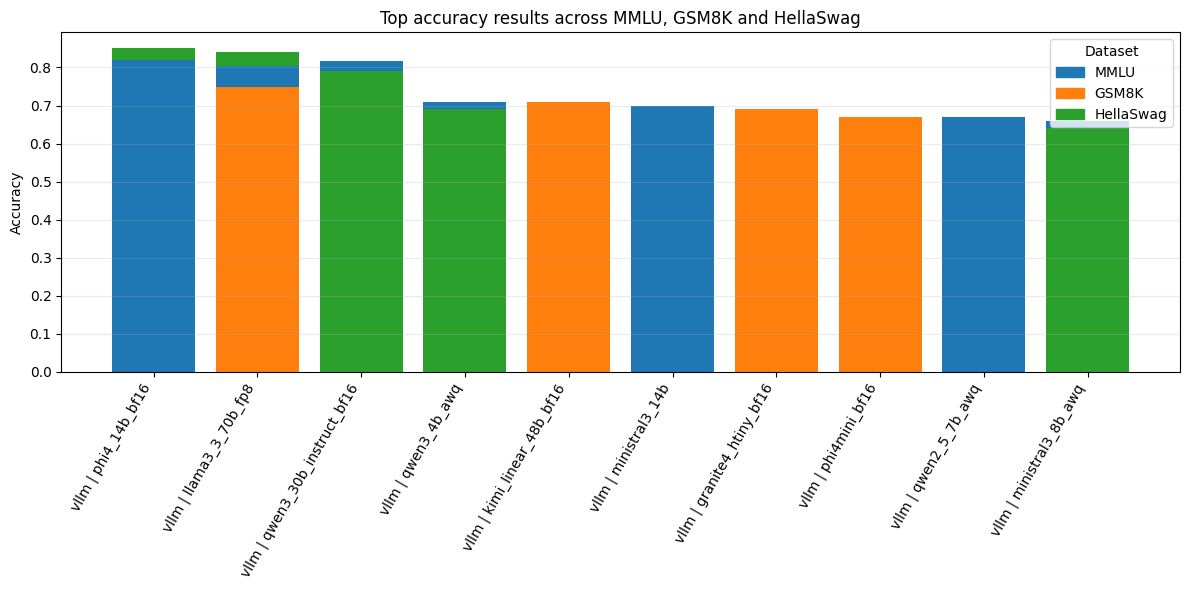

In [33]:
acc = summary[summary["dataset"].isin(["mmlu", "gsm8k", "hellaswag"])].dropna(subset=["accuracy"]).copy()
acc["platform_model"] = acc["platform"] + " | " + acc["model"]

# Keep top 20 by accuracy for readability.
acc_top = acc.sort_values("accuracy", ascending=False).head(20)
plt.figure(figsize=(12, 6))
colors = [DATASET_COLORS.get(d, "gray") for d in acc_top["dataset"]]
plt.bar(acc_top["platform_model"], acc_top["accuracy"], color=colors)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Accuracy")
plt.title("Top accuracy results across MMLU, GSM8K and HellaSwag")
handles = [plt.Rectangle((0,0),1,1,color=DATASET_COLORS[d]) for d in ["mmlu","gsm8k","hellaswag"]]
plt.legend(handles, ["MMLU", "GSM8K", "HellaSwag"], title="Dataset")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Figure 2 — Accuracy vs latency

The accuracy/latency trade-off is the primary decision plot for scored datasets. The preferred region is the upper-left: high accuracy and low latency. The metadata shows that **llama3_2_1b_bf16** is the fastest model on MMLU and HellaSwag, but the top accuracy models are **phi4_14b_bf16** and **llama3_3_70b_fp8** depending on the dataset. This means the fastest model is not automatically the best model when correctness matters.


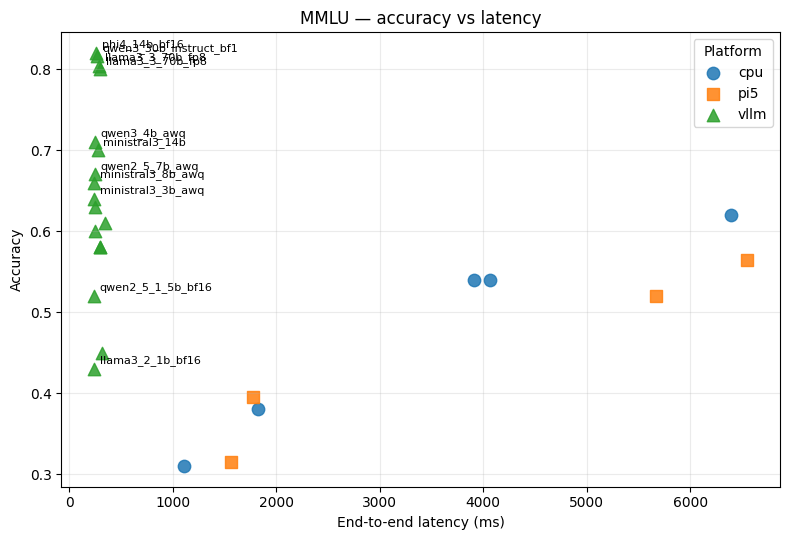

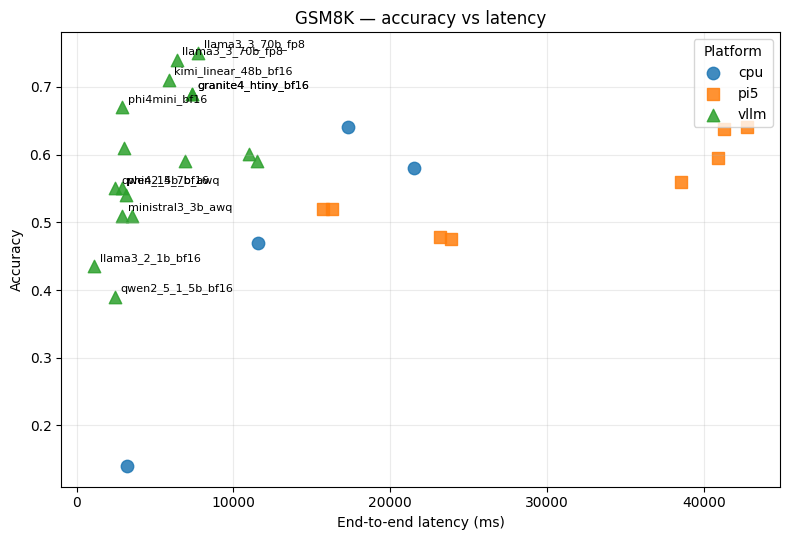

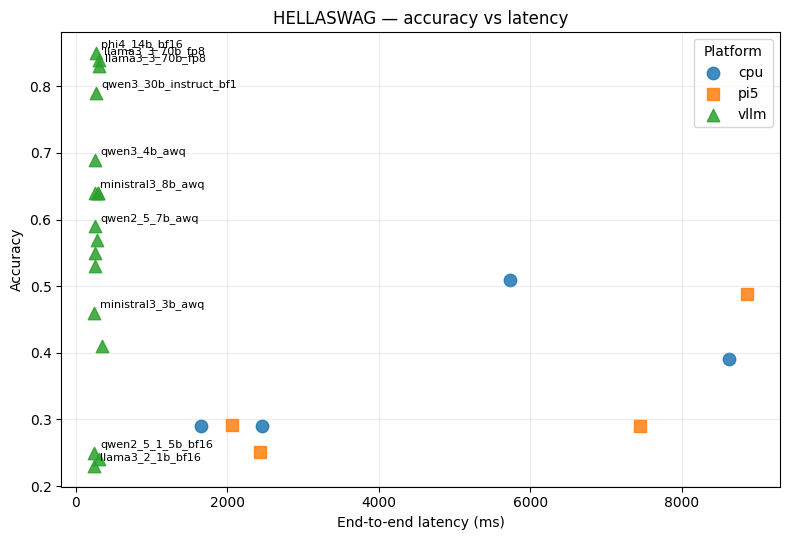

In [34]:
scored = summary[summary["dataset"].isin(["mmlu", "gsm8k", "hellaswag"])].dropna(subset=["accuracy", "latency_ms"]).copy()

for ds in ["mmlu", "gsm8k", "hellaswag"]:
    sub = scored[scored["dataset"] == ds]
    plt.figure(figsize=(8, 5.5))
    for platform, g in sub.groupby("platform"):
        plt.scatter(g["latency_ms"], g["accuracy"], label=platform, marker=PLATFORM_MARKERS.get(platform, "o"), s=80, alpha=0.85)
        for _, row in g.iterrows():
            if row["accuracy"] >= sub["accuracy"].quantile(0.80) or row["latency_ms"] <= sub["latency_ms"].quantile(0.20):
                plt.annotate(row["model"][:22], (row["latency_ms"], row["accuracy"]), fontsize=8, xytext=(4,4), textcoords="offset points")
    plt.xlabel("End-to-end latency (ms)")
    plt.ylabel("Accuracy")
    plt.title(f"{ds.upper()} — accuracy vs latency")
    plt.legend(title="Platform")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


## Figure 3 — Accuracy vs throughput

This figure distinguishes fast generation from useful generation. On GSM8K, vLLM provides the highest throughput, with **llama3_2_1b_bf16** reaching 116.653 tokens/s, but the best GSM8K accuracy is **llama3_3_70b_fp8** at 0.75. The correct interpretation is that vLLM gives the best serving envelope, while model choice inside vLLM still depends on the required accuracy level.


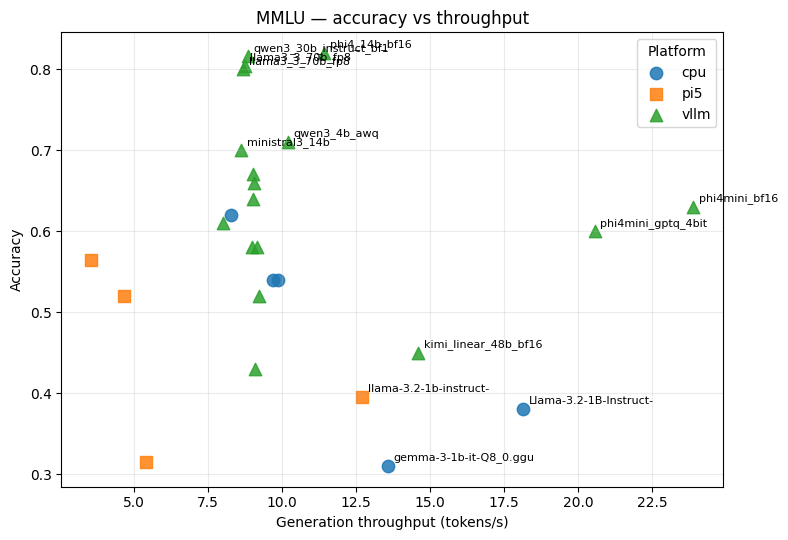

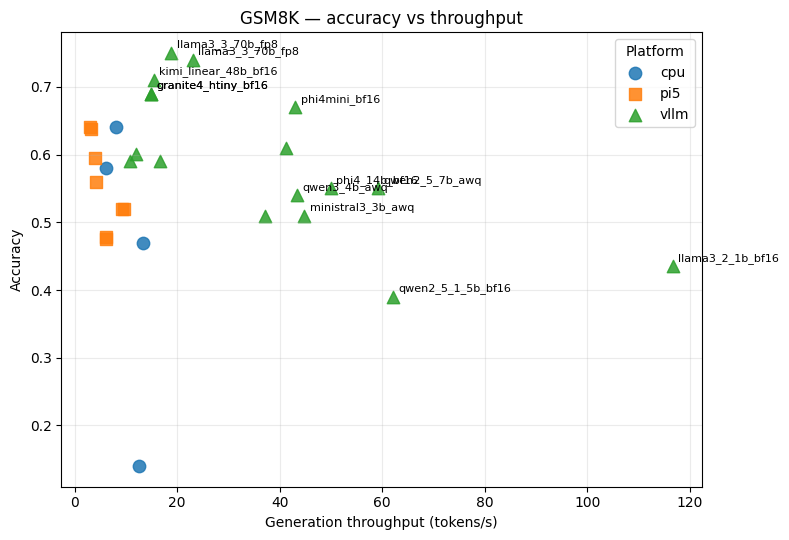

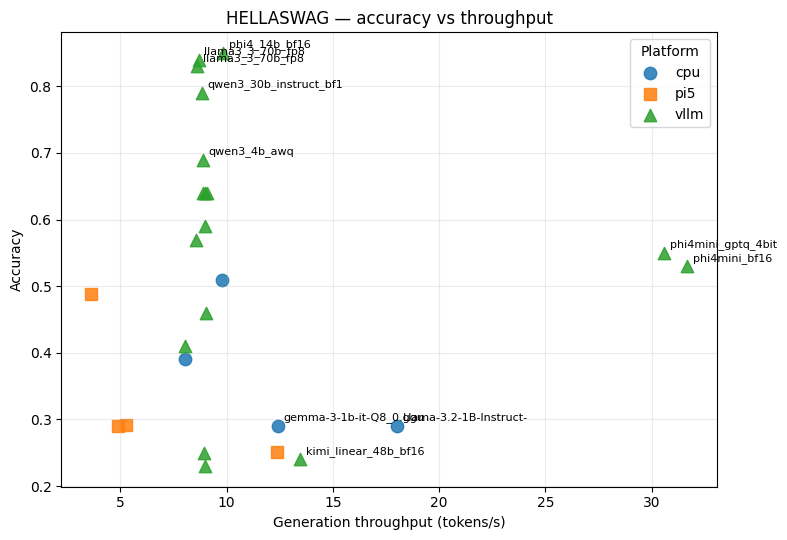

In [35]:
for ds in ["mmlu", "gsm8k", "hellaswag"]:
    sub = scored[scored["dataset"] == ds].dropna(subset=["tokens_per_sec"])
    plt.figure(figsize=(8, 5.5))
    for platform, g in sub.groupby("platform"):
        plt.scatter(g["tokens_per_sec"], g["accuracy"], label=platform, marker=PLATFORM_MARKERS.get(platform, "o"), s=80, alpha=0.85)
        for _, row in g.iterrows():
            if row["accuracy"] >= sub["accuracy"].quantile(0.80) or row["tokens_per_sec"] >= sub["tokens_per_sec"].quantile(0.80):
                plt.annotate(row["model"][:22], (row["tokens_per_sec"], row["accuracy"]), fontsize=8, xytext=(4,4), textcoords="offset points")
    plt.xlabel("Generation throughput (tokens/s)")
    plt.ylabel("Accuracy")
    plt.title(f"{ds.upper()} — accuracy vs throughput")
    plt.legend(title="Platform")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


## Figure 4 — GPU/vLLM energy efficiency

Energy is only meaningful where power is measured, so this analysis is restricted to vLLM. The metadata shows that **llama3_2_1b_bf16** has the lowest estimated energy on MMLU, GSM8K, HellaSwag, and Dolly. This is an efficiency result, not a quality result: the same model is not the highest-accuracy model on all scored datasets.


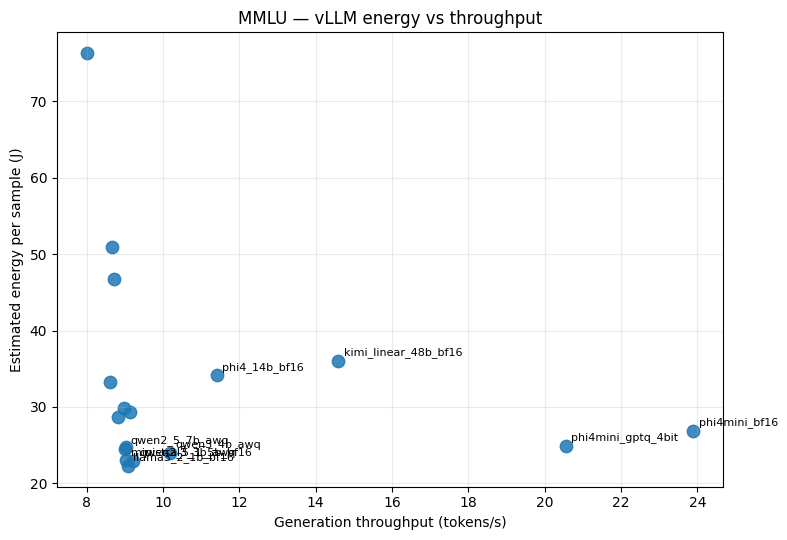

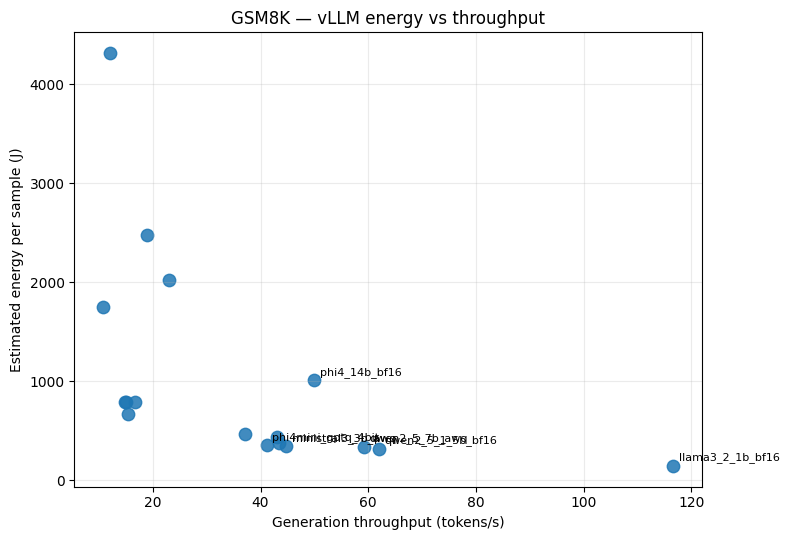

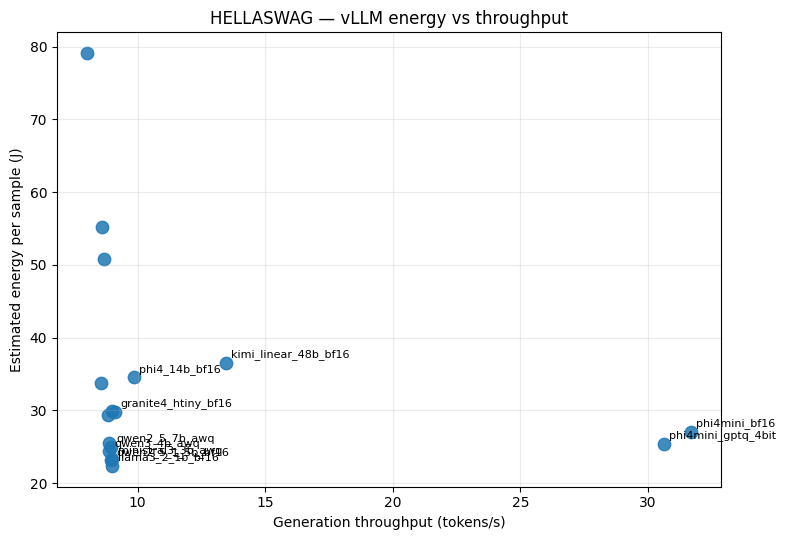

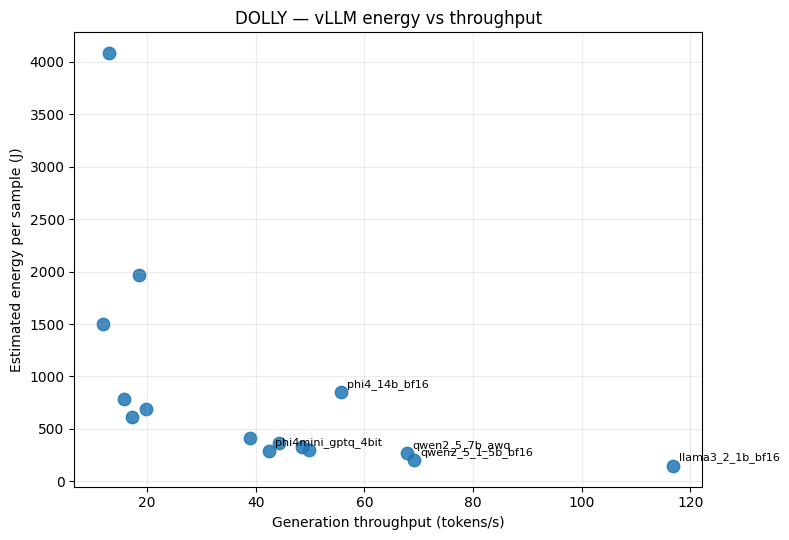

In [36]:
gpu = summary[summary["platform"] == "vllm"].copy()
if "energy_j" in gpu.columns:
    for ds in ["mmlu", "gsm8k", "hellaswag", "dolly"]:
        sub = gpu[gpu["dataset"] == ds].dropna(subset=["energy_j", "tokens_per_sec"])
        if sub.empty:
            continue
        plt.figure(figsize=(8, 5.5))
        plt.scatter(sub["tokens_per_sec"], sub["energy_j"], s=80, alpha=0.85)
        for _, row in sub.iterrows():
            if row["energy_j"] <= sub["energy_j"].quantile(0.25) or row["tokens_per_sec"] >= sub["tokens_per_sec"].quantile(0.75):
                plt.annotate(row["model"][:24], (row["tokens_per_sec"], row["energy_j"]), fontsize=8, xytext=(4,4), textcoords="offset points")
        plt.xlabel("Generation throughput (tokens/s)")
        plt.ylabel("Estimated energy per sample (J)")
        plt.title(f"{ds.upper()} — vLLM energy vs throughput")
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()
else:
    print("No energy_j column available.")


## Figure 5 — Dolly generation workload

Dolly is interpreted as performance-only because no accuracy score is computed. The metadata shows that **llama3_2_1b_bf16** is the strongest vLLM Dolly model on latency, throughput, sustained throughput, samples/s, and estimated energy. This makes it the best pure performance choice for this workload, while answer quality remains outside the benchmark.


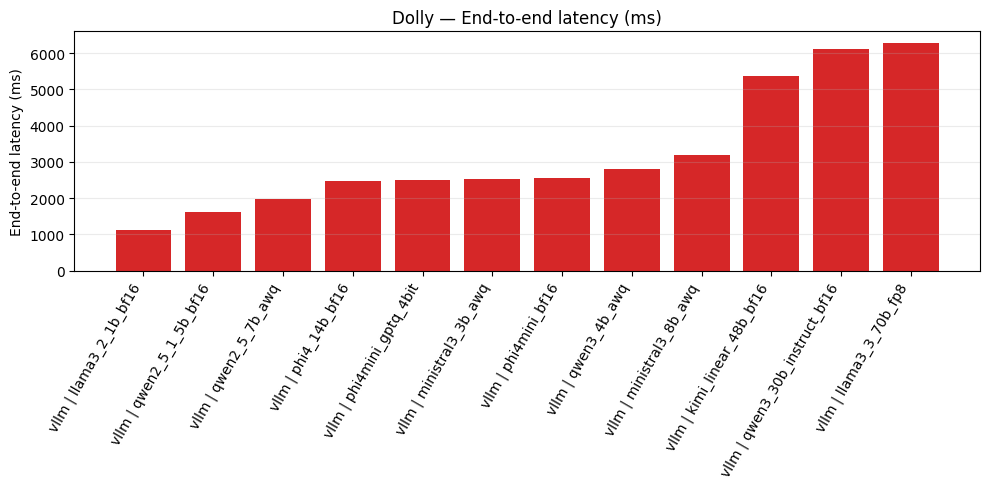

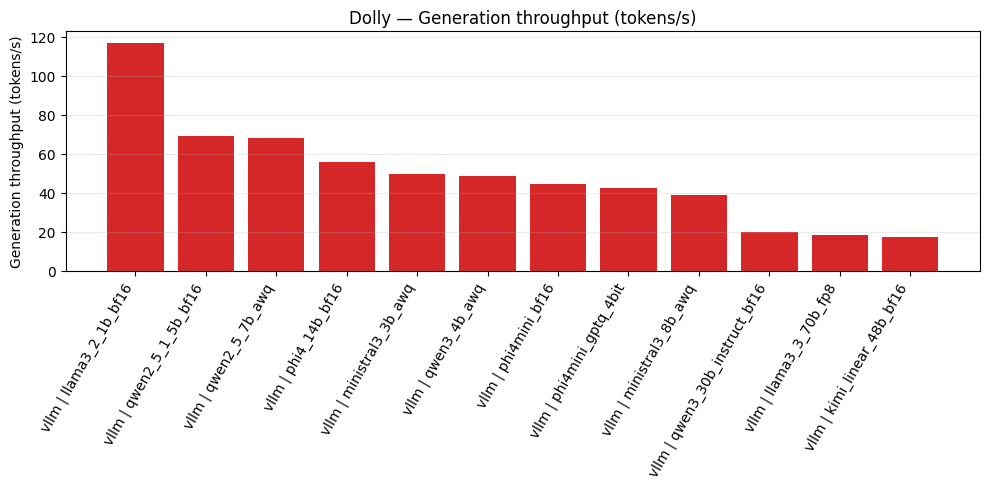

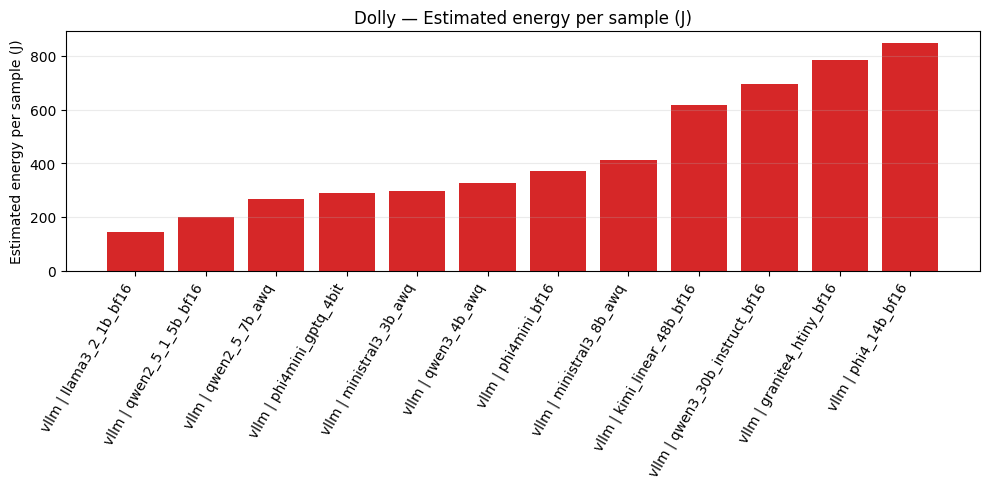

In [37]:
dolly = summary[summary["dataset"] == "dolly"].copy()
metrics = ["latency_ms", "tokens_per_sec", "energy_j"]
for metric in metrics:
    if metric not in dolly.columns:
        continue
    sub = dolly.dropna(subset=[metric]).copy()
    if sub.empty:
        continue
    ascending = metric in ["latency_ms", "energy_j"]
    sub = sub.sort_values(metric, ascending=ascending).head(12)
    plt.figure(figsize=(10, 5))
    plt.bar(sub["platform"] + " | " + sub["model"], sub[metric], color="tab:red")
    plt.xticks(rotation=60, ha="right")
    plt.ylabel(METRIC_LABELS.get(metric, metric))
    plt.title(f"Dolly — {METRIC_LABELS.get(metric, metric)}")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


## Figure 6 — CPU and Pi5 edge interpretation

For CPU and Pi5, the main finding is that the accuracy winner is often different from the latency or throughput winner. On Pi5, **Phi-4-mini-instruct-Q4_K_M.gguf** is the strongest accuracy model on MMLU, GSM8K, and HellaSwag, but it is also the weakest or slowest on several latency and memory metrics. For edge deployment, this is the central trade-off: smaller models are more responsive, while stronger models improve accuracy at a resource cost.


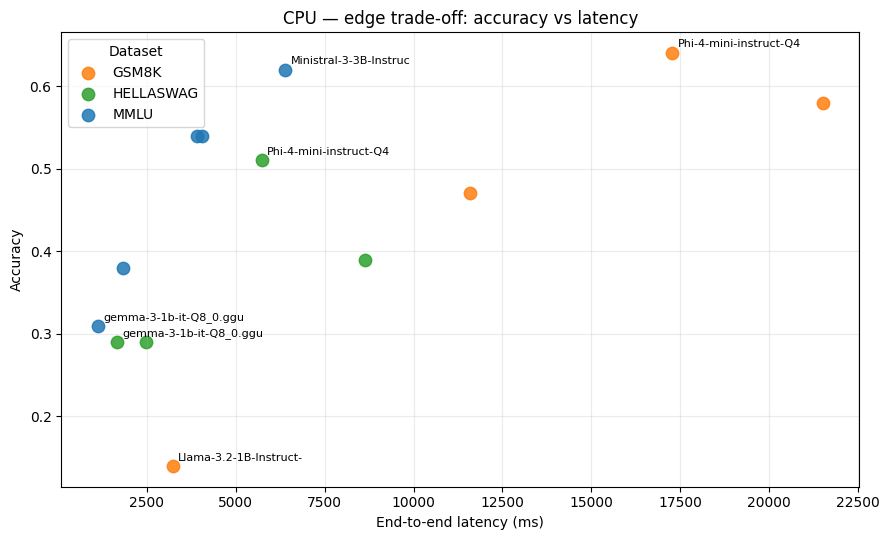

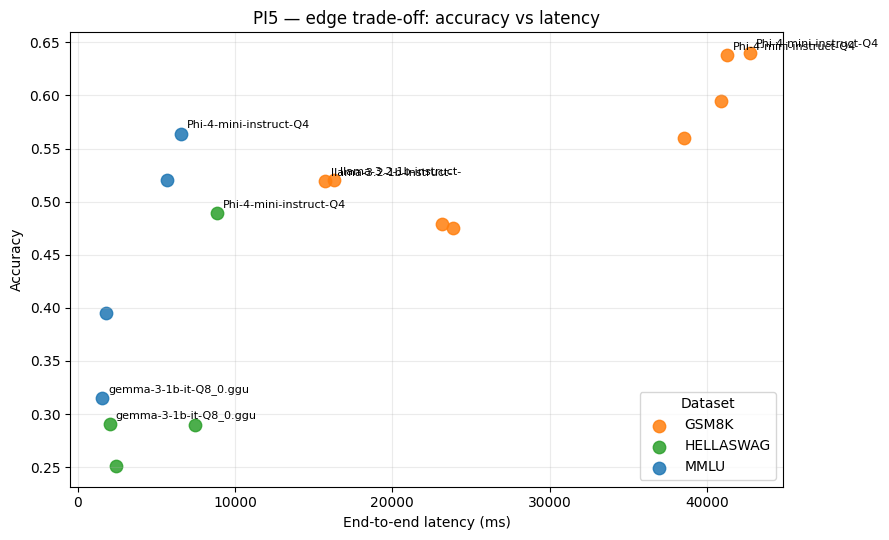

In [38]:
edge = summary[summary["platform"].isin(["cpu", "pi5"]) & summary["dataset"].isin(["mmlu", "gsm8k", "hellaswag"])].copy()
for platform in ["cpu", "pi5"]:
    subp = edge[edge["platform"] == platform]
    plt.figure(figsize=(9, 5.5))
    for ds, g in subp.groupby("dataset"):
        plt.scatter(g["latency_ms"], g["accuracy"], label=ds.upper(), color=DATASET_COLORS.get(ds), s=80, alpha=0.85)
        for _, row in g.iterrows():
            if row["accuracy"] >= g["accuracy"].quantile(0.80) or row["latency_ms"] <= g["latency_ms"].quantile(0.20):
                plt.annotate(row["model"][:22], (row["latency_ms"], row["accuracy"]), fontsize=8, xytext=(4,4), textcoords="offset points")
    plt.xlabel("End-to-end latency (ms)")
    plt.ylabel("Accuracy")
    plt.title(f"{platform.upper()} — edge trade-off: accuracy vs latency")
    plt.legend(title="Dataset")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


## Ranking tables

These tables are the concise numerical basis for the conclusions above. They identify the metric winners without requiring manual inspection of every generated figure.


In [39]:
def show_winners(dataset, metric, high=True, n=8):
    sub = summary[summary["dataset"] == dataset].dropna(subset=[metric]).copy()
    if sub.empty:
        return
    sub = sub.sort_values(metric, ascending=not high).head(n)
    cols = ["platform", "model", "dataset", metric]
    display(sub[cols].reset_index(drop=True))

for dataset in ["mmlu", "gsm8k", "hellaswag"]:
    print(f"\n{dataset.upper()} — top accuracy")
    show_winners(dataset, "accuracy", high=True, n=8)
    print(f"{dataset.upper()} — lowest latency")
    show_winners(dataset, "latency_ms", high=False, n=8)

print("\nDOLLY — highest throughput")
show_winners("dolly", "tokens_per_sec", high=True, n=8)
print("DOLLY — lowest energy")
show_winners("dolly", "energy_j", high=False, n=8)



MMLU — top accuracy


,platform,model,dataset,accuracy
0,vllm,phi4_14b_bf16,mmlu,0.820
1,vllm,qwen3_30b_instruct_bf16,mmlu,0.816
2,vllm,llama3_3_70b_fp8,mmlu,0.804
3,vllm,llama3_3_70b_fp8,mmlu,0.800
4,vllm,qwen3_4b_awq,mmlu,0.710
5,vllm,ministral3_14b,mmlu,0.700
6,vllm,qwen2_5_7b_awq,mmlu,0.670
7,vllm,ministral3_8b_awq,mmlu,0.660


MMLU — lowest latency


,platform,model,dataset,latency_ms
0,vllm,llama3_2_1b_bf16,mmlu,239.4302
1,vllm,ministral3_3b_awq,mmlu,241.5101
2,vllm,qwen2_5_1_5b_bf16,mmlu,242.3532
3,vllm,ministral3_8b_awq,mmlu,244.4214
4,vllm,qwen2_5_7b_awq,mmlu,246.5590
5,vllm,qwen3_4b_awq,mmlu,247.4329
6,vllm,phi4mini_bf16,mmlu,251.2127
7,vllm,phi4mini_gptq_4bit,mmlu,252.8680



GSM8K — top accuracy


...

,platform,model,dataset,latency_ms
0,vllm,llama3_2_1b_bf16,hellaswag,240.5751
1,vllm,ministral3_3b_awq,hellaswag,242.9518
2,vllm,qwen2_5_1_5b_bf16,hellaswag,245.6957
3,vllm,qwen2_5_7b_awq,hellaswag,248.2488
4,vllm,ministral3_8b_awq,hellaswag,249.2464
5,vllm,phi4mini_bf16,hellaswag,249.2533
6,vllm,qwen3_4b_awq,hellaswag,250.2470
7,vllm,phi4mini_gptq_4bit,hellaswag,252.8561



DOLLY — highest throughput


,platform,model,dataset,tokens_per_sec
0,vllm,llama3_2_1b_bf16,dolly,116.8876
1,vllm,qwen2_5_1_5b_bf16,dolly,69.2146
2,vllm,qwen2_5_7b_awq,dolly,67.8415
3,vllm,phi4_14b_bf16,dolly,55.7300
4,vllm,ministral3_3b_awq,dolly,49.8161
5,vllm,qwen3_4b_awq,dolly,48.4553
6,vllm,phi4mini_bf16,dolly,44.1783
7,vllm,phi4mini_gptq_4bit,dolly,42.5035


DOLLY — lowest energy


,platform,model,dataset,energy_j
0,vllm,llama3_2_1b_bf16,dolly,145.482145
1,vllm,qwen2_5_1_5b_bf16,dolly,199.609501
2,vllm,qwen2_5_7b_awq,dolly,266.658690
3,vllm,phi4mini_gptq_4bit,dolly,290.043980
4,vllm,ministral3_3b_awq,dolly,294.722947
5,vllm,qwen3_4b_awq,dolly,327.171017
6,vllm,phi4mini_bf16,dolly,370.012752
7,vllm,ministral3_8b_awq,dolly,413.610323


## Cleaned figure-commentary appendix

The previous draft contained editable placeholders such as “Your final note”. Those have been removed. The cleaned auto-commentary file is generated by the next cell and can be used as an appendix if a figure-by-figure report is needed.


In [40]:
if auto_commentary_path is None:
    print("figure_commentary_auto.md was not found, so no cleaned commentary appendix was generated.")
else:
    text = Path(auto_commentary_path).read_text(encoding="utf-8")

    text = text.replace(
        "These comments are first-pass analytical text generated from the data behind each figure. Edit them for final report style.",
        "These comments are generated from the metric metadata behind each figure."
    )
    text = re.sub(r"\n\*\*Your final note:\*\*\n\n_Edit or extend this paragraph with your own interpretation\\._\n", "\n", text)
    text = text.replace(
        "This figure should be interpreted together with accuracy and latency because optimizing only",
        "This figure is interpreted together with quality and deployment cost because optimizing only"
    )

    clean_path = Path(auto_commentary_path).parent / "figure_commentary_cleaned.md"
    clean_path.write_text(text, encoding="utf-8")
    print("Cleaned commentary written to:", clean_path)

    # Preview first part only.
    print(text[:3000])

Cleaned commentary written to: /home/stephane/resource-efficiency-benchmark/notebooks/results/report_grade_visualizations/figure_commentary_cleaned.md
# Auto-generated figure commentary

These comments are generated from the metric metadata behind each figure.

## Bar — GSM8K — CPU — accuracy

**Figure file:** `results/report_grade_visualizations/bar_gsm8k_cpu_accuracy_bar.png`

For GSM8K on CPU, the best model by Accuracy is **Phi-4-mini-instruct-Q4_K_M.gguf** with highest value **0.64**. The weakest model on the same metric is **Llama-3.2-1B-Instruct-Q8_0.gguf** with **0.14**. This figure is interpreted together with quality and deployment cost because optimizing only Accuracy may hide a quality or deployment trade-off.

**Your final note:**

_Edit or extend this paragraph with your own interpretation._

---

## Bar — GSM8K — CPU — latency_ms

**Figure file:** `results/report_grade_visualizations/bar_gsm8k_cpu_latency_ms_bar.png`

For GSM8K on CPU, the best model by End-to-end latenc

## Final conclusion

The benchmark shows that model selection is deployment-specific.

For **quality-sensitive scored tasks**, vLLM provides the strongest absolute results in this metadata: **phi4_14b_bf16** leads MMLU and HellaSwag accuracy, while **llama3_3_70b_fp8** leads GSM8K accuracy. For **lowest latency and energy**, **llama3_2_1b_bf16** is repeatedly the best vLLM model, including Dolly.

For **CPU and Pi5**, the best choice depends on the constraint. **Phi-4-mini-instruct-Q4_K_M.gguf** is often the best local/edge accuracy model, especially on GSM8K and Pi5, but smaller models such as **Llama-3.2-1B** and **gemma-3-1b** provide better latency or throughput. This is the expected edge trade-off: correctness costs memory and time.

Dolly should not be used to make quality claims. It supports claims about generation latency, throughput, energy, and resource pressure only. In this run, **llama3_2_1b_bf16** is the strongest vLLM Dolly performance model.

The practical recommendation is therefore:

- Use **vLLM larger/stronger models** when accuracy is the priority.
- Use **llama3_2_1b_bf16 on vLLM** when latency, throughput, and energy dominate.
- Use **Phi-4-mini** on CPU/Pi5 when local accuracy matters.
- Use **smaller CPU/Pi5 models** when responsiveness and memory footprint dominate.
